# Bahrain Rental Price Prediction — Deep Learning
**Adam Ameer Isa Ali · Neural-network regression with Keras**

**Goal:** predict monthly `rent` in Bahraini dinars (BHD) and evaluate with **Mean Absolute Error (MAE)**. Lower is better.

This version follows your gradient-descent and Keras lectures: prepare the data, scale features, build dense layers, compile with Adam, train with early stopping, and inspect learning curves. It also compares a categorical-embedding network with a conventional dense network.

**How to run:** use a Python environment with TensorFlow (for example, Google Colab). Put `property_data.csv`, `test.csv`, and optionally `sample_submission.csv` beside this notebook, or in a `data` folder. If needed, run `%pip install tensorflow pandas numpy scikit-learn matplotlib seaborn joblib` in a temporary setup cell, restart the kernel, then run this notebook from top to bottom. All imports are in the first code cell.

**Evaluation changes:** the supplied notebook reports 104.75 BHD OOF MAE after clipping targets and excluding some property types. Here we retain all valid positive rents and all property types. We use separate training, tuning-validation, and held-out evaluation groups. These scores are therefore **not directly comparable** with that earlier number. No leaderboard score below 70 is assumed or promised.

The competition test set has no labels. Our **holdout** is a labeled subset of the training CSV, used once after selecting the architecture on validation data. Listing URLs define groups; this prevents known repeated URLs crossing splits, but does not detect every possible duplicate property.

## Results from the executed experiment

The selected model is **embedding_small**, with **44 epochs** selected on validation data.

| Evaluation | MAE (BHD) | Meaning |
|---|---:|---|
| Validation, all original rents | 270.51 | Used to choose the model; not an independent final estimate. |
| Holdout, all original rents | 144.39 | Separate evaluation of the selected single model. |
| Holdout, rents at most 3,000 BHD | 109.62 | Diagnostic subset only; not the full competition distribution. |
| Training-median baseline, full holdout | 290.67 | Constant-prediction reference on the same holdout. |

**This run did not achieve MAE below 70.** Its scores should not be compared directly with the previous notebook's 104.75 BHD score, which used clipped targets, a different population, and different splits. The final three-seed ensemble was refitted on all 32,090 valid labeled rows and produced 3,566 test predictions. Its leaderboard MAE remains unknown.

All code cells were executed on the supplied data. The final saved models were reloaded and reproduced the predictions. The downloadable CSV is the final ensemble's competition-test submission, not predictions for the training rows.


## 1. Imports
Load every library used in the notebook. TensorFlow performs automatic differentiation and Keras provides the layers, Adam optimizer, and callbacks used in your lectures.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
import re
import json
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, TerminateOnNaN
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

### 1.1 Reproducibility and experiment settings
Use fixed seeds and restrained thread counts. Each candidate may train for up to 100 epochs, with early stopping after 12 epochs without improvement. The final ensemble trains three fresh networks on all labeled data, using the selected epoch count. Predictions are non-negative; no upper rent cap is imposed.

In [2]:
SEED = 42
MAX_EPOCHS = 100
PATIENCE = 12
BATCH_SIZE = 256
TARGET_SCALE = 500.0
FINAL_SEEDS = [42, 137, 2026]
OUTPUT_DIR = Path("deep_learning_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
try:
    tf.config.threading.set_inter_op_parallelism_threads(2)
    tf.config.threading.set_intra_op_parallelism_threads(2)
except RuntimeError:
    pass  # Thread settings are already fixed if TensorFlow was used earlier.
sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 2. Load the data
Resolve common dataset filenames without silently choosing between duplicate files. Preserve test identifiers as strings. The sample submission is optional, but when present its ID order is used only if its IDs match the current test file.

In [3]:
def find_csv(names, required=True):
    for folder in [Path("."), Path("data"), Path("../data")]:
        matches = [folder / name for name in names if (folder / name).exists()]
        if len(matches) > 1:
            raise ValueError(f"Multiple candidate files in {folder}: {matches}. Keep one or set paths explicitly.")
        if matches:
            return matches[0]
    if required:
        raise FileNotFoundError(f"Provide one of {names} beside the notebook or in data/.")
    return None

TRAIN_PATH = find_csv(["property_data.csv", "property_data(1).csv", "data.csv"])
TEST_PATH = find_csv(["test.csv", "test(1).csv"])
SAMPLE_PATH = find_csv(["sample_submission.csv", "sample_submission(1).csv"], required=False)
train_raw = pd.read_csv(TRAIN_PATH, dtype={"Property_id": "string"})
test_raw = pd.read_csv(TEST_PATH, dtype={"Property_id": "string"})
sample = pd.read_csv(SAMPLE_PATH, dtype={"Property_id": "string"}) if SAMPLE_PATH else None
assert "rent" in train_raw and "Property_id" in test_raw
assert test_raw["Property_id"].notna().all() and test_raw["Property_id"].is_unique
print("Training:", train_raw.shape, "Competition test:", test_raw.shape)
display(train_raw.head())

Training: (32090, 41) Competition test: (3566, 40)


,Unnamed: 0,Property_id,property_type,offer,governorate,bedrooms,bathrooms,rent,location,city,...,is_super_agent,broker_id,floor_plans,is_featured,is_premium,description,is_verified,is_verified.1,is_exclusive,is_exclusive.1
0,27387,7343b863-a2cb-4d85-b2dd-935ea61365ff,Apartment,Residential for Rent,"Capital Governorate, Manama",studio,1,245.0,NaN,NaN,...,True,1031.0,NaN,False,False,A different furnished studio opportunity in Sa...,False,False,False,False
1,18554,f1a36ab5-1601-4127-a7a7-5095f167acca,Apartment,Rent,Capital Governorate,1,1,300.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9295,bf629ae9-a3b2-4c2e-8e0e-b0ffce916fa7,Compound,Rent,Northern Governorate,5,5,1200.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,28118,26707746-825c-4d65-b63c-dfaa69421365,Apartment,Residential for Rent,Capital Governorate,3,3,600.0,NaN,NaN,...,False,15.0,NaN,True,False,Spacious 3 Bedroom Apartment for Rent in Seef ...,False,False,False,False
4,689,dbc18ce8-1481-480c-9b66-a42653038408,Apartment,for rent,Muharraq Governorate,1,2,450.0,Al Marsa Floating City,Amwaj Islands,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Exploratory Data Analysis (EDA)
Inspect missingness, category counts, and rent percentiles. In this dataset the rent range includes extremely expensive listings, so a log-scaled plot helps display the entire distribution without removing observations.

,dtype,missing_pct,unique_values
price_per_sqm,float64,100.000000,0
completion_status,float64,100.000000,0
floor_plans,float64,100.000000,0
down_payment,float64,100.000000,0
payment_methods,str,99.320661,3
plot_size_sqm,float64,92.327828,265
location,str,90.966033,63
city,str,74.428171,56
availability_date,str,71.748208,584
agency,str,70.314740,202


count     32090.000000
mean        695.558461
std        6643.256725
min          50.000000
1%          150.000000
50%         450.000000
90%        1100.000000
95%        1400.000000
99%        1905.500000
99.9%      6645.760000
max      950000.000000
Name: rent, dtype: float64

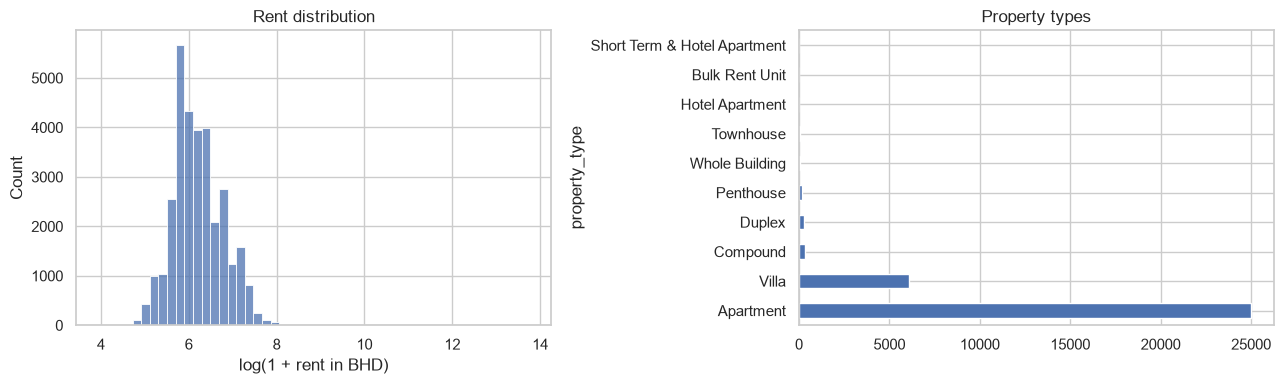

In [4]:
summary = pd.DataFrame({"dtype": train_raw.dtypes.astype(str),
                        "missing_pct": train_raw.isna().mean() * 100,
                        "unique_values": train_raw.nunique()})
display(summary.sort_values("missing_pct", ascending=False))
rent_raw = pd.to_numeric(train_raw["rent"], errors="coerce")
display(rent_raw.describe(percentiles=[.01, .5, .9, .95, .99, .999]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(np.log1p(rent_raw[rent_raw > 0]), bins=50, ax=axes[0])
axes[0].set(xlabel="log(1 + rent in BHD)", title="Rent distribution")
train_raw["property_type"].fillna("Unknown").value_counts().head(10).plot.barh(ax=axes[1])
axes[1].set_title("Property types")
plt.tight_layout()
plt.show()

## 4. Target handling and known duplicate groups
Remove only rows whose targets are missing, non-finite, or non-positive. Keep the original valid rent values, including outliers, so the reported MAE uses actual labels. `price_per_sqm`, target-derived flags, identifiers, and free-text prices are excluded from model inputs.

Normalize URLs for grouping, removing query strings and fragments. Missing URLs get individual group labels. This is a duplicate-control measure, not a guarantee that every repeated property is identified.

In [5]:
valid_target = rent_raw.notna() & np.isfinite(rent_raw) & rent_raw.gt(0)
train = train_raw.loc[valid_target].reset_index(drop=True).copy()
train["rent"] = rent_raw.loc[valid_target].to_numpy(dtype=float)
y = train["rent"].to_numpy(dtype=np.float32)
urls = train.get("URL", pd.Series("", index=train.index)).fillna("").astype(str).str.strip()
urls = urls.str.replace(r"[?#].*$", "", regex=True).str.rstrip("/")
groups = np.array([f"url:{u}" if u else f"missing_url_row:{i}" for i, u in enumerate(urls)])
print("Invalid targets removed:", int((~valid_target).sum()))
print("Retained rows:", len(train), "Unique URL groups:", len(np.unique(groups)))
print("Rents above 3,000 BHD retained:", int((y > 3000).sum()))

Invalid targets removed: 0
Retained rows: 32090 Unique URL groups: 31524
Rents above 3,000 BHD retained: 77


## 5. Feature Engineering
### 5.1 Parse rooms and area
Convert studios to zero bedrooms; extract room counts from mixed text. Prefer the sqm part of mixed-unit area strings and convert sqft-only values to sqm. Unparseable or non-positive areas become missing. The same functions are used for training and test data.

In [6]:
def parse_area(value):
    if pd.isna(value):
        return np.nan
    s = str(value).lower().replace(",", "").strip()
    m = re.search(r"(\d+(?:\.\d+)?)\s*(?:sqm|m²|m2)", s)
    if m:
        result = float(m.group(1))
    else:
        m = re.search(r"(\d+(?:\.\d+)?)\s*(?:sqft|sq\s*ft|ft²)", s)
        if m:
            result = float(m.group(1)) * 0.09290304
        else:
            try:
                result = float(s)
            except ValueError:
                return np.nan
    return result if np.isfinite(result) and result > 0 else np.nan

def parse_rooms(value):
    if pd.isna(value):
        return np.nan
    text = str(value).lower()
    if "studio" in text:
        return 0.0
    match = re.search(r"\d+", text)
    return float(match.group()) if match else np.nan

def clean_text(series):
    return (series.fillna("").astype(str).str.lower().str.strip()
            .str.replace(r"\s+", " ", regex=True).replace("", "__missing__"))

### 5.2 Structural, location, and amenity features
Create area-per-room ratios, log area, geographic coordinates, and indicators for amenities and selected title keywords. Extract governorate and neighborhood separately and retain detailed location categories. Category embeddings later learn compact numerical representations of these labels.

Only the explicitly listed input fields are used. Raw title/description text is not fed to the network; the title contributes only the fixed keyword indicators below. No rent-based feature or target encoding is created.

In [7]:
AMENITIES = {
    "pool": "pool", "private_pool": "private pool", "gym": "gym",
    "security": "security", "concierge": "concierge", "balcony": "balcony",
    "garden": "garden", "maid_service": "maid service", "maids_room": "maid",
    "sea_view": "view of water|sea view", "central_ac": "central a/c|central ac",
    "kitchen": "kitchen appliances", "parking": "parking", "study": "study",
    "wardrobes": "wardrobes", "children": "children", "beach": "beach"
}
TITLE_TERMS = {"luxury": "luxury", "new": "brand new", "sea_view": "sea view",
               "spacious": "spacious", "maid": "maid", "balcony": "balcony",
               "pool": "pool", "garden": "garden"}
CAT_COLS = ["property_type", "governorate_main", "neighborhood", "city", "location",
            "location_full", "furnished", "include_w_e", "period", "offer", "agency"]

def engineer_features(raw):
    def col(name):
        return raw[name] if name in raw else pd.Series(np.nan, index=raw.index)
    out = pd.DataFrame(index=raw.index)
    out["area_sqm_num"] = col("area_sqm").map(parse_area)
    out["bedrooms_num"] = col("bedrooms").map(parse_rooms)
    out["bathrooms_num"] = col("bathrooms").map(parse_rooms)
    out["maid_room"] = clean_text(col("bedrooms")).str.contains("maid", regex=False).astype(float)
    out["log_area"] = np.log1p(out["area_sqm_num"])
    out["area_per_bedroom"] = out["area_sqm_num"] / (out["bedrooms_num"] + 1)
    out["baths_per_bedroom"] = out["bathrooms_num"] / (out["bedrooms_num"] + 1)
    lat = pd.to_numeric(col("latitude"), errors="coerce")
    lon = pd.to_numeric(col("longitude"), errors="coerce")
    geo_ok = lat.between(25, 27) & lon.between(49, 52)
    out["latitude"], out["longitude"] = lat.where(geo_ok), lon.where(geo_ok)
    out["has_geo"] = geo_ok.astype(float)
    out["distance_manama_km"] = np.sqrt(((out["latitude"] - 26.2285) * 111)**2 +
                                           ((out["longitude"] - 50.5860) * 102)**2)
    amen = clean_text(col("amenities"))
    has_text = ~amen.eq("__missing__") & ~amen.str.fullmatch(r"[\d\s,.]+", na=False)
    out["amenity_text_available"] = has_text.astype(float)
    out["amenity_count"] = amen.str.split(",").str.len().where(has_text, 0).astype(float)
    for name, pattern in AMENITIES.items():
        out["has_" + name] = (has_text & amen.str.contains(pattern, regex=True)).astype(float)
    title = clean_text(col("title"))
    for name, pattern in TITLE_TERMS.items():
        out["title_" + name] = title.str.contains(pattern, regex=False).astype(float)
    for name in ["is_featured", "is_premium", "is_super_agent", "is_verified"]:
        out[name + "_flag"] = clean_text(col(name)).map({"true":1., "false":0., "1":1., "0":0., "yes":1., "no":0.})
    for name in CAT_COLS:
        if name not in ["governorate_main", "neighborhood"]:
            out[name] = clean_text(col(name))
    gov = clean_text(col("governorate"))
    out["governorate_main"] = gov.str.split(",").str[0].str.strip()
    out["neighborhood"] = gov.map(lambda s: s.split(",", 1)[1].strip() if "," in s else "__missing__")
    return out.replace([np.inf, -np.inf], np.nan)

X = engineer_features(train)
X_test = engineer_features(test_raw).reindex(columns=X.columns)
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]
assert not {"rent", "price_per_sqm", "Property_id", "rent_was_clipped"}.intersection(X.columns)
assert X.columns.equals(X_test.columns)
print("Numerical features:", len(NUM_COLS), "Categorical features:", len(CAT_COLS))
display(X.head())

Numerical features: 42 Categorical features: 11


,area_sqm_num,bedrooms_num,bathrooms_num,maid_room,log_area,area_per_bedroom,baths_per_bedroom,latitude,longitude,has_geo,...,city,location,location_full,furnished,include_w_e,period,offer,agency,governorate_main,neighborhood
0,43.0,0.0,1.0,0.0,3.784190,43.000000,1.000000,26.226559,50.545910,1.0,...,__missing__,__missing__,"sanabis, manama, capital governorate",yes,inclusive,monthly,residential for rent,__missing__,capital governorate,manama
1,65.0,1.0,1.0,0.0,4.189655,32.500000,0.500000,NaN,NaN,0.0,...,__missing__,__missing__,__missing__,__missing__,inclusive,__missing__,rent,deccan real estate,capital governorate,__missing__
2,400.0,5.0,5.0,0.0,5.993961,66.666667,0.833333,NaN,NaN,0.0,...,__missing__,__missing__,__missing__,__missing__,exclusive,__missing__,rent,aqaratcom for real estate,northern governorate,__missing__
3,160.0,3.0,3.0,0.0,5.081404,40.000000,0.750000,26.240000,50.536999,1.0,...,__missing__,__missing__,"seef, capital governorate",yes,inclusive,monthly,residential for rent,__missing__,capital governorate,__missing__
4,80.0,1.0,2.0,0.0,4.394449,40.000000,1.000000,NaN,NaN,0.0,...,amwaj islands,al marsa floating city,__missing__,__missing__,__missing__,__missing__,for rent,__missing__,muharraq governorate,__missing__


## 6. Training, Validation, and Holdout Split
Hold out approximately 20% of listing groups for final evaluation. Split the remainder into training and validation groups, giving approximately 60%/20%/20% overall. Group sizes can make the row proportions differ slightly.

We fit preprocessing on training rows only, choose the model and stopping epoch using validation rows, and evaluate the selected model once on the holdout. Save the split assignment for reproducibility.

In [8]:
outer = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED)
dev_idx, holdout_idx = next(outer.split(X, y, groups))
inner = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED + 1)
a, b = next(inner.split(X.iloc[dev_idx], y[dev_idx], groups[dev_idx]))
train_idx, val_idx = dev_idx[a], dev_idx[b]
for left, right in [(train_idx, val_idx), (train_idx, holdout_idx), (val_idx, holdout_idx)]:
    assert not set(groups[left]).intersection(groups[right])
split_labels = np.full(len(X), "train", dtype=object)
split_labels[val_idx], split_labels[holdout_idx] = "validation", "holdout"
pd.DataFrame({"Property_id": train["Property_id"], "split": split_labels}).to_csv(OUTPUT_DIR / "split_assignments.csv", index=False)
print(pd.Series(split_labels).value_counts())

train         19250
holdout        6423
validation     6417
Name: count, dtype: int64


## 7. Preprocessing for Neural Networks
### 7.1 Training-only imputation, scaling, and category vocabularies
For each numeric feature, learn the 0.5th and 99.5th percentile bounds, fill missing values with its median, and apply robust scaling. Missingness flags retain information about absent values. These bounds affect **inputs only**, never the target.

For categories, keep labels seen at least three times in the training split and map rare or unseen labels to index 0. The basic network uses one-hot encoding; the embedding network consumes integer indices. All learned values are refitted on all labeled data only after holdout evaluation.

In [9]:
def fit_preprocessor(frame):
    numeric = frame[NUM_COLS].astype(float).replace([np.inf, -np.inf], np.nan)
    lower, upper = numeric.quantile(.005), numeric.quantile(.995)
    bounded = numeric.clip(lower=lower, upper=upper, axis=1)
    medians = bounded.median().fillna(0.)
    scaler = RobustScaler().fit(bounded.fillna(medians))
    vocab = {}
    for c in CAT_COLS:
        counts = frame[c].value_counts()
        kept = sorted(counts[counts >= 3].index.tolist())
        vocab[c] = {value: i+1 for i, value in enumerate(kept)}
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
    cat_ids = np.column_stack([frame[c].map(vocab[c]).fillna(0).astype("int32") for c in CAT_COLS])
    enc.fit(cat_ids)
    return {"lower":lower, "upper":upper, "medians":medians, "scaler":scaler,
            "vocab":vocab, "onehot":enc, "numeric_columns":NUM_COLS, "categorical_columns":CAT_COLS}

def transform_features(frame, prep):
    numeric = frame[prep["numeric_columns"]].astype(float).replace([np.inf, -np.inf], np.nan)
    missing = numeric.isna().to_numpy(dtype=np.float32)
    bounded = numeric.clip(lower=prep["lower"], upper=prep["upper"], axis=1)
    scaled = prep["scaler"].transform(bounded.fillna(prep["medians"]))
    numeric_array = np.concatenate([scaled, missing], axis=1).astype(np.float32)
    ids = np.column_stack([frame[c].map(prep["vocab"][c]).fillna(0).to_numpy(dtype=np.int32) for c in CAT_COLS])
    basic = np.concatenate([numeric_array, prep["onehot"].transform(ids)], axis=1).astype(np.float32)
    embedded = {"numeric":numeric_array, **{f"cat_{j}":ids[:, j:j+1] for j in range(len(CAT_COLS))}}
    assert np.isfinite(basic).all()
    return {"basic":{"features":basic}, "embedding":embedded}

prep = fit_preprocessor(X.iloc[train_idx])
train_inputs = transform_features(X.iloc[train_idx], prep)
val_inputs = transform_features(X.iloc[val_idx], prep)
print("Dense input dimensions:", train_inputs["basic"]["features"].shape)
print("Category vocabulary sizes:", {c:len(v) for c,v in prep["vocab"].items()})

Dense input dimensions: (19250, 495)
Category vocabulary sizes: {'property_type': 12, 'governorate_main': 5, 'neighborhood': 10, 'city': 44, 'location': 53, 'location_full': 108, 'furnished': 4, 'include_w_e': 4, 'period': 2, 'offer': 3, 'agency': 161}


### 7.2 Target scaling and batches
Divide rent by the constant 500 during optimization. This is **linear scaling**, not log transformation or clipping:

$$\operatorname{MAE}(y/500,\widehat y/500)=\operatorname{MAE}(y,\widehat y)/500.$$

Therefore minimizing scaled MAE minimizes MAE in BHD. Convert every reported prediction back to BHD. Shuffle training rows, keep evaluation order fixed, and limit TensorFlow's data-loader threads.

In [10]:
def make_dataset(inputs, target=None, training=False, seed=SEED):
    if target is None:
        ds = tf.data.Dataset.from_tensor_slices(inputs)
    else:
        ds = tf.data.Dataset.from_tensor_slices((inputs, np.asarray(target, dtype=np.float32).reshape(-1, 1) / TARGET_SCALE))
    if training:
        ds = ds.shuffle(len(next(iter(inputs.values()))), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(BATCH_SIZE).with_options(options).prefetch(1)

def predict_bhd(model, inputs):
    pred = model.predict(make_dataset(inputs), verbose=0).reshape(-1) * TARGET_SCALE
    return np.maximum(pred, 0.)

def regression_scores(actual, prediction):
    return {"MAE_BHD":float(mean_absolute_error(actual, prediction)),
            "RMSE_BHD":float(np.sqrt(mean_squared_error(actual, prediction))),
            "R2":float(r2_score(actual, prediction))}

## 8. Build the Neural Networks
### 8.1 Dense baseline and categorical embeddings
The basic model follows your lecture's dense-network structure: an input layer, ReLU hidden layers, and one **linear output neuron** for regression. Dropout and L2 regularization discourage overfitting.

The embedding model learns a small vector for each category, joins those vectors with the numeric features, then passes the combined features through dense layers. Both networks use **Adam** and **MAE loss**. A linear output is appropriate here; classification softmax and accuracy are not used. The output bias starts at the training median rent divided by 500.

In [11]:
def build_network(config, transformed, prep, target, seed):
    keras.utils.set_random_seed(seed)
    if config["kind"] == "basic":
        inp = keras.Input(shape=(transformed["basic"]["features"].shape[1],), name="features")
        inputs, hidden = {"features":inp}, inp
    else:
        numeric = keras.Input(shape=(transformed["embedding"]["numeric"].shape[1],), name="numeric")
        inputs, pieces = {"numeric":numeric}, [numeric]
        for j, col in enumerate(CAT_COLS):
            size = len(prep["vocab"][col]) + 1
            inp = keras.Input(shape=(1,), dtype="int32", name=f"cat_{j}")
            inputs[f"cat_{j}"] = inp
            dim = min(24, max(2, int(np.sqrt(size)) + 1))
            emb = layers.Embedding(size, dim, embeddings_regularizer=regularizers.l2(1e-6))(inp)
            pieces.append(layers.Flatten()(emb))
        hidden = layers.Concatenate()(pieces)
    for width in config["widths"]:
        hidden = layers.Dense(width, activation="relu", kernel_regularizer=regularizers.l2(1e-5))(hidden)
        hidden = layers.Dropout(config["dropout"])(hidden)
    output = layers.Dense(1, activation="linear", name="scaled_rent",
                          bias_initializer=keras.initializers.Constant(float(np.median(target)/TARGET_SCALE)))(hidden)
    model = keras.Model(inputs=inputs, outputs=output, name=config["name"])
    model.compile(optimizer=Adam(learning_rate=config["learning_rate"], clipnorm=5.0),
                  loss="mae", metrics=[keras.metrics.MeanAbsoluteError(name="mae")])
    return model

CONFIGS = [
    {"name":"dense_baseline", "kind":"basic", "widths":[128,64], "dropout":.10, "learning_rate":.001},
    {"name":"embedding_small", "kind":"embedding", "widths":[128,64], "dropout":.10, "learning_rate":.001},
    {"name":"embedding_deeper", "kind":"embedding", "widths":[256,128,64], "dropout":.15, "learning_rate":.0007}
]
example_model = build_network(CONFIGS[0], train_inputs, prep, y[train_idx], SEED)
example_model.summary()
del example_model

Model: "dense_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 495)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        63,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_rent (Dense)             │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,809 (280.50 KB)

 Trainable params: 71,809 (280.50 KB)

 Non-trainable params: 0 (0.00 B)

### 8.2 Train and select on validation MAE
Train the three predetermined architectures. Early stopping monitors `val_mae`, restores the best weights, and saves each fitted candidate plus its history. The holdout remains unused.

Validation MAE is a **selection score**, not an unbiased final estimate. We choose the architecture with the smallest validation MAE after applying the same non-negative prediction rule used for the submission.

In [12]:
results, histories, validation_predictions = [], {}, {}
for config in CONFIGS:
    keras.backend.clear_session()
    model = build_network(config, train_inputs, prep, y[train_idx], SEED)
    kind = config["kind"]
    stop = EarlyStopping(monitor="val_mae", mode="min", patience=PATIENCE,
                         restore_best_weights=True, min_delta=0.)
    history = model.fit(make_dataset(train_inputs[kind], y[train_idx], training=True),
                        validation_data=make_dataset(val_inputs[kind], y[val_idx]),
                        epochs=MAX_EPOCHS, callbacks=[stop, TerminateOnNaN()], verbose=0)
    hist = pd.DataFrame(history.history)
    if not np.isfinite(hist[["loss", "val_mae"]].to_numpy()).all():
        raise RuntimeError(f"Non-finite training results for {config['name']}")
    pred_train = predict_bhd(model, train_inputs[kind])
    pred_val = predict_bhd(model, val_inputs[kind])
    best_epoch = int(hist["val_mae"].argmin() + 1)
    row = {"model":config["name"], "train_MAE_BHD":mean_absolute_error(y[train_idx], pred_train),
           "validation_MAE_BHD":mean_absolute_error(y[val_idx], pred_val), "best_epoch":best_epoch,
           "epochs_run":len(hist)}
    results.append(row)
    histories[config["name"]] = hist
    validation_predictions[config["name"]] = pred_val
    model.save(OUTPUT_DIR / f"candidate_{config['name']}.keras")
    hist.to_csv(OUTPUT_DIR / f"history_{config['name']}.csv", index=False)
    print(row, flush=True)
    del model
    gc.collect()

comparison = pd.DataFrame(results).sort_values("validation_MAE_BHD").reset_index(drop=True)
comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)
best_name = comparison.iloc[0]["model"]
best_config = next(c for c in CONFIGS if c["name"] == best_name)
best_epochs = int(comparison.iloc[0]["best_epoch"])
display(comparison)
print("Selected architecture:", best_name, "Selected epoch count:", best_epochs)

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'model': 'dense_baseline', 'train_MAE_BHD': 212.89187622070312, 'validation_MAE_BHD': 271.0335388183594, 'best_epoch': 21, 'epochs_run': 33}


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'model': 'embedding_small', 'train_MAE_BHD': 220.3374481201172, 'validation_MAE_BHD': 271.09783935546875, 'best_epoch': 25, 'epochs_run': 37}


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{'model': 'embedding_deeper', 'train_MAE_BHD': 227.8294219970703, 'validation_MAE_BHD': 273.6565856933594, 'best_epoch': 17, 'epochs_run': 29}


,model,train_MAE_BHD,validation_MAE_BHD,best_epoch,epochs_run
0,dense_baseline,212.891876,271.033539,21,33
1,embedding_small,220.337448,271.097839,25,37
2,embedding_deeper,227.829422,273.656586,17,29


Selected architecture: dense_baseline Selected epoch count: 21


## 9. Learning Curves and Validation Comparison
Plot training and validation MAE in BHD. Training history includes dropout during learning, whereas validation is measured with dropout disabled; this can partly explain why validation curves occasionally lie below training curves. Compare the model against a constant training-median prediction.

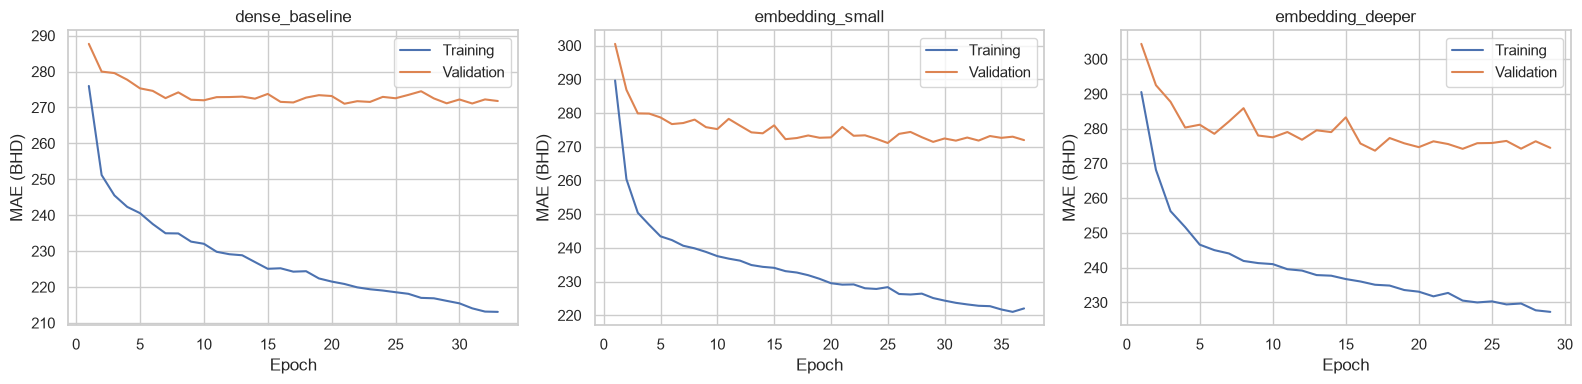

Training-median baseline validation MAE: 424.84899485741


In [13]:
fig, axes = plt.subplots(1, len(CONFIGS), figsize=(16, 4))
for ax, config in zip(axes, CONFIGS):
    hist = histories[config["name"]]
    ax.plot(np.arange(1, len(hist)+1), hist["mae"] * TARGET_SCALE, label="Training")
    ax.plot(np.arange(1, len(hist)+1), hist["val_mae"] * TARGET_SCALE, label="Validation")
    ax.set(title=config["name"], xlabel="Epoch", ylabel="MAE (BHD)")
    ax.legend()
plt.tight_layout()
plt.show()
median_rent = float(np.median(y[train_idx]))
print("Training-median baseline validation MAE:",
      mean_absolute_error(y[val_idx], np.full(len(val_idx), median_rent)))

## 10. Held-Out Evaluation
### 10.1 Evaluate the selected model once
Load the model chosen using validation results and evaluate it on untouched holdout groups. Report MAE on **all original holdout targets**, RMSE, and R². Extreme rents can dominate the full-distribution metrics; the following section shows their contribution rather than modifying those targets.

This measures the selected single model trained on the training split. The final three-seed ensemble is subsequently refitted on all labeled rows; its competition test MAE is unknown until submission.

In [14]:
selected_model = keras.models.load_model(OUTPUT_DIR / f"candidate_{best_name}.keras")
holdout_inputs = transform_features(X.iloc[holdout_idx], prep)
holdout_pred = predict_bhd(selected_model, holdout_inputs[best_config["kind"]])
holdout_scores = regression_scores(y[holdout_idx], holdout_pred)
median_scores = regression_scores(y[holdout_idx], np.full(len(holdout_idx), median_rent))
display(pd.DataFrame([{"model":"training_median", **median_scores},
                      {"model":best_name, **holdout_scores}]))
print("Holdout targets > 3,000 BHD:", int((y[holdout_idx] > 3000).sum()))
print("Holdout MAE below 70 BHD:", holdout_scores["MAE_BHD"] < 70)

,model,MAE_BHD,RMSE_BHD,R2
0,training_median,290.666667,1440.406329,-0.012568
1,dense_baseline,142.098846,1393.898221,0.051764


Holdout targets > 3,000 BHD: 11
Holdout MAE below 70 BHD: False


### 10.2 Error analysis
Inspect errors by property type, governorate, and rent band. Subset metrics are diagnostic only and must not replace the full-holdout score. The actual-versus-predicted plot uses logarithmic axes to display the broad price range. Review large errors for possible data-quality issues before any later experiment.

,count,mean,median
property_type,,,
land,1,1761.116211,1761.116211
whole building,9,1165.624146,904.358154
bulk rent unit,2,311.066437,311.066437
hotel apartment,3,302.231934,349.437012
penthouse,39,284.485931,192.692749
compound,66,213.704926,174.986450
villa,1199,212.378448,149.729614
duplex,62,132.997192,54.929535
apartment,5033,121.192406,50.995789


,count,mean,median
governorate_main,,,
northern governorate,1200,155.915588,94.432465
muharraq governorate,1716,155.027451,55.592026
southern governorate,206,149.429031,64.314560
capital governorate,3106,130.865845,57.836929
central governorate,195,114.478889,51.882996


,count,mean,median
rent_band,,,
>3000,11,20116.787109,2123.320068
1000–3000,719,322.283905,253.918213
500–1000,1828,135.078094,107.783020
300–500,2480,58.082989,44.128235
0–300,1385,49.621326,39.178650


,property_type,governorate_main,Property_id,actual_rent,predicted_rent,absolute_error,rent_band
3122,apartment,muharraq governorate,425371ce-a00c-4d4c-9fac-a8b1c858441d,72000.0,353.630066,71646.367188,>3000
2054,apartment,capital governorate,1a88a1e7-11fb-4978-84f1-aeab89e0f4ad,68000.0,507.001587,67493.000000,>3000
5289,apartment,capital governorate,1c5061f3-60a8-4197-b926-a347b60df72a,40000.0,313.348267,39686.652344,>3000
3292,apartment,muharraq governorate,750dbc36-a9cf-4eea-96c8-ea958783e447,31500.0,283.425995,31216.574219,>3000
5164,whole building,southern governorate,b221f25f-2ae0-485d-a1ef-c107d76451e6,5160.0,1533.370728,3626.629395,>3000
2724,apartment,central governorate,c9d7dd2c-7ff5-4b85-ac1b-4b61f105e896,3000.0,763.349548,2236.650391,1000–3000
5599,villa,muharraq governorate,424ec92e-6cce-4e58-bd8e-936ff8fadb90,3500.0,1376.679932,2123.320068,>3000
1014,duplex,muharraq governorate,4910bc5b-d06c-4c1b-9890-3d6f340bcad5,2800.0,815.766907,1984.233154,1000–3000
4901,apartment,central governorate,5d1c6790-eb3c-4939-8d52-d549334d53b0,3000.0,1023.608459,1976.391602,1000–3000
1280,whole building,northern governorate,e15898f4-7920-4c65-a104-84ff007d9278,600.0,2472.607422,1872.607422,500–1000


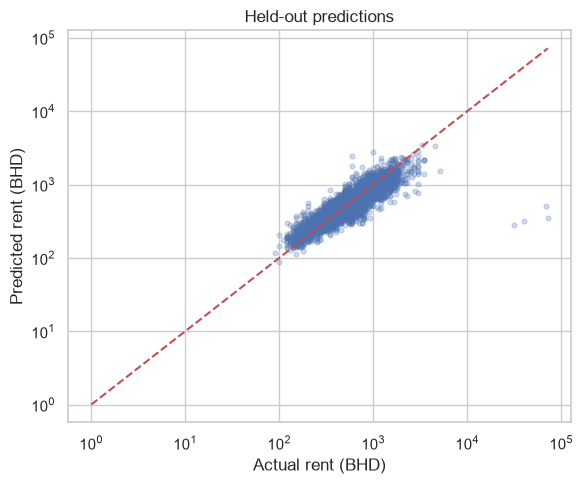

In [15]:
errors = X.iloc[holdout_idx][["property_type", "governorate_main"]].reset_index(drop=True).copy()
errors["Property_id"] = train.iloc[holdout_idx]["Property_id"].to_numpy()
errors["actual_rent"], errors["predicted_rent"] = y[holdout_idx], holdout_pred
errors["absolute_error"] = np.abs(errors["actual_rent"] - errors["predicted_rent"])
errors["rent_band"] = pd.cut(errors["actual_rent"], [0, 300, 500, 1000, 3000, np.inf],
                             labels=["0–300", "300–500", "500–1000", "1000–3000", ">3000"])
for col in ["property_type", "governorate_main", "rent_band"]:
    display(errors.groupby(col, observed=True)["absolute_error"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False))
display(errors.nlargest(10, "absolute_error"))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(errors["actual_rent"], np.maximum(errors["predicted_rent"], 1), alpha=.25, s=12)
limits = [1, max(errors["actual_rent"].max(), errors["predicted_rent"].max())]
ax.plot(limits, limits, "r--")
ax.set(xscale="log", yscale="log", xlabel="Actual rent (BHD)", ylabel="Predicted rent (BHD)", title="Held-out predictions")
plt.tight_layout()
plt.show()
errors.to_csv(OUTPUT_DIR / "holdout_predictions.csv", index=False)

## 11. Final Training on All Labeled Data
Refit preprocessing on all valid labeled rows. Train the selected architecture from scratch with three different seeds, using the epoch count already chosen on validation. Average their predictions to reduce variation caused by initialization and training order.

There is no early stopping in this step because all labeled data is now used for training. Save preprocessing and each model so they can be reused. The competition test data never fits the scaler or category vocabularies.

In [16]:
del selected_model
keras.backend.clear_session()
final_prep = fit_preprocessor(X)
full_inputs = transform_features(X, final_prep)
competition_inputs = transform_features(X_test, final_prep)
joblib.dump(final_prep, OUTPUT_DIR / "preprocessor.joblib")
seed_predictions = []
for seed in FINAL_SEEDS:
    keras.backend.clear_session()
    model = build_network(best_config, full_inputs, final_prep, y, seed)
    kind = best_config["kind"]
    history = model.fit(make_dataset(full_inputs[kind], y, training=True, seed=seed),
                        epochs=best_epochs, callbacks=[TerminateOnNaN()], verbose=0)
    assert len(history.history["loss"]) == best_epochs
    assert np.isfinite(history.history["loss"]).all()
    pred = predict_bhd(model, competition_inputs[kind])
    assert len(pred) == len(test_raw) and np.isfinite(pred).all()
    seed_predictions.append(pred)
    model.save(OUTPUT_DIR / f"final_seed_{seed}.keras")
    print(f"Seed {seed}: trained {best_epochs} epochs; prediction median = {np.median(pred):.2f} BHD", flush=True)
    del model
    gc.collect()
final_predictions = np.mean(seed_predictions, axis=0)

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Seed 42: trained 21 epochs; prediction median = 437.04 BHD
Seed 137: trained 21 epochs; prediction median = 441.84 BHD
Seed 2026: trained 21 epochs; prediction median = 435.78 BHD


## 12. Create and Check the Submission
Create `submission_deep_learning.csv` with exactly `Property_id,Rent`. Use only competition test rows and preserve all IDs. Follow sample-submission order only when its IDs match the current test set; otherwise explicitly report the mismatch and use test-file order. Retain decimal predictions and check length, unique IDs, missing values, finiteness, and non-negativity.

**Detected in the supplied files:** the older sample template has 3,527 numeric IDs and a lowercase `rent` column. The current test dataset has 3,566 UUIDs. The current test IDs and the requested `Property_id,Rent` specification are authoritative for this submission.

In [17]:
submission = pd.DataFrame({"Property_id":test_raw["Property_id"].astype(str), "Rent":final_predictions})
expected_ids = test_raw["Property_id"].astype(str).tolist()
if sample is not None:
    requested_ids = sample["Property_id"].astype(str)
    sample_matches = (sample["Property_id"].notna().all() and requested_ids.is_unique
                      and set(requested_ids) == set(submission["Property_id"]))
    if sample_matches:
        submission = submission.set_index("Property_id").loc[requested_ids].reset_index()
        expected_ids = requested_ids.tolist()
    else:
        print(f"Sample template mismatch ({len(sample)} sample rows vs {len(test_raw)} test rows). "
              "Using the current test IDs/order and required Property_id,Rent columns.")
assert submission.columns.tolist() == ["Property_id", "Rent"]
assert len(submission) == len(test_raw)
assert submission["Property_id"].tolist() == expected_ids
assert submission["Property_id"].is_unique and not submission.isna().any().any()
assert np.isfinite(submission["Rent"]).all() and submission["Rent"].ge(0).all()
submission_path = OUTPUT_DIR / "submission_version2.csv"
submission.to_csv(submission_path, index=False)
check = pd.read_csv(submission_path, dtype={"Property_id":"string"})
assert check["Property_id"].tolist() == expected_ids
assert np.allclose(check["Rent"], submission["Rent"])
display(submission.head(10))
display(submission["Rent"].describe())
print("Saved:", submission_path.resolve(), "Rows:", len(submission))

Sample template mismatch (3527 sample rows vs 3566 test rows). Using the current test IDs/order and required Property_id,Rent columns.


,Property_id,Rent
0,25c91c33-a523-42f2-8c10-9f340005471d,449.511078
1,6bcb7804-9cd7-4792-8cbe-abb4de65058a,233.545029
2,7b733e67-ec21-4427-95f8-4be3d9d18f6b,1082.999634
3,feefd51f-a7d6-45b0-a9eb-200d9f9821b4,373.356659
4,cca286dd-ddc6-41c2-9584-f8e17461220f,450.943756
5,cc9b3f89-6263-4bf8-bbdb-3d8fb8509243,429.518066
6,e70723a0-3c99-4d02-bb58-ea679b3e2053,322.929565
7,08b5bd2c-546f-479d-bae1-ef6ced64cbf0,715.290710
8,a8596600-6030-4229-9c13-1e26fceb4409,532.895935
9,3d5181fe-7bce-4f03-a57b-ed1ef415355f,226.589615


count    3566.000000
mean      564.879517
std       356.510742
min       103.751503
25%       337.801636
50%       438.418732
75%       681.406799
max      4418.928711
Name: Rent, dtype: float64

Saved: C:\DESK TOP FILES\Tamkeen Data Science Bootcamp\Tamkeen Lectures\Visual Studio Code\deep_learning_outputs\submission_version2.csv Rows: 3566


## 13. Save the Experiment Record
Save the selected architecture, validation score, holdout metrics, seed list, target scale, training policy, and software versions. The prior notebook's 104.75 BHD score is contextual only because its labels and validation procedure differed.

In [18]:
metadata = {"selected_config":best_config, "selected_epochs":best_epochs,
            "validation_MAE_BHD":float(comparison.iloc[0]["validation_MAE_BHD"]),
            "holdout_single_model":holdout_scores, "median_baseline_holdout":median_scores,
            "final_seeds":FINAL_SEEDS, "target_scale":TARGET_SCALE,
            "target_policy":"Retain every finite positive original rent; no clipping",
            "split_policy":"URL-grouped train/validation/holdout; approximate 60/20/20",
            "training_rows":len(train), "competition_test_rows":len(test_raw),
            "tensorflow_version":tf.__version__, "numpy_version":np.__version__,
            "pandas_version":pd.__version__,
            "competition_test_MAE":None}
(OUTPUT_DIR / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(json.dumps(metadata, indent=2))

{
  "selected_config": {
    "name": "dense_baseline",
    "kind": "basic",
    "widths": [
      128,
      64
    ],
    "dropout": 0.1,
    "learning_rate": 0.001
  },
  "selected_epochs": 21,
  "validation_MAE_BHD": 271.0335388183594,
  "holdout_single_model": {
    "MAE_BHD": 142.09884643554688,
    "RMSE_BHD": 1393.8982208181485,
    "R2": 0.05176436901092529
  },
  "median_baseline_holdout": {
    "MAE_BHD": 290.6666666666667,
    "RMSE_BHD": 1440.406328577421,
    "R2": -0.01256790968130117
  },
  "final_seeds": [
    42,
    137,
    2026
  ],
  "target_scale": 500.0,
  "target_policy": "Retain every finite positive original rent; no clipping",
  "split_policy": "URL-grouped train/validation/holdout; approximate 60/20/20",
  "training_rows": 32090,
  "competition_test_rows": 3566,
  "tensorflow_version": "2.21.0",
  "numpy_version": "2.5.2",
  "pandas_version": "3.0.5",
  "competition_test_MAE": null
}


## 14. Reload the Saved Ensemble
This reproducibility check reloads all three models and the saved preprocessing, recomputes the test predictions, and verifies that they match the submitted values before sample-order alignment. Run the parsing and feature-engineering definitions above before using these artifacts in a new session. Only load joblib files you trust.

In [19]:
reloaded_prep = joblib.load(OUTPUT_DIR / "preprocessor.joblib")
reloaded_inputs = transform_features(engineer_features(test_raw).reindex(columns=X.columns), reloaded_prep)
reloaded_predictions = []
for seed in FINAL_SEEDS:
    restored = keras.models.load_model(OUTPUT_DIR / f"final_seed_{seed}.keras", compile=False)
    reloaded_predictions.append(predict_bhd(restored, reloaded_inputs[best_config["kind"]]))
    del restored
assert np.allclose(np.mean(reloaded_predictions, axis=0), final_predictions, rtol=1e-5, atol=1e-3)
print("Reload check passed: saved models reproduce the final predictions.")

Reload check passed: saved models reproduce the final predictions.


## 15. Connection to Your Lectures and Interpretation

| Lecture concept | How it appears here |
|---|---|
| Gradient descent | Adam uses gradients computed by backpropagation to update weights in mini-batches. |
| Feature scaling | Training-only median imputation and robust scaling stabilize numeric inputs. |
| Dense layers and ReLU | Hidden layers learn nonlinear relationships between property features and rent. |
| Regression output | One linear neuron predicts scaled rent, converted back to BHD. |
| Loss and metrics | MAE is the optimization loss and the competition metric; regularization adds to total loss. |
| Validation and early stopping | Validation MAE selects the architecture and stopping epoch; holdout groups provide a separate evaluation. |
| Classification lecture | Its compile/fit/callback workflow transfers, but softmax, class weights, accuracy, and confusion matrices do not apply to rent regression. |
| Extensions | Embeddings learn category vectors; dropout and L2 regularize the network; three seeds provide a final average. |

**Reading the result:** trust the all-row holdout MAE for the selected single model. A score computed only for a rent band answers a narrower question. The final ensemble's leaderboard score must be measured by submitting its CSV. Deep learning is an experiment here, not a guarantee of beating the existing tree models.

**References:** your uploaded `02-gradient-descent.ipynb`, `Intro to Deep Learning.ipynb`, `NN-Classification.ipynb`, and rental notebook; [Keras EarlyStopping](https://keras.io/api/callbacks/early_stopping/), [Keras structured-data example](https://keras.io/examples/structured_data/structured_data_classification_from_scratch/), and [Keras training and evaluation](https://keras.io/guides/training_with_built_in_methods/).